# EDA: выбор уточняющего вопроса при неполном ответе

**Анна Губарева · 8 ноября 2026 · Research / NLP.**

Задача проекта — выбирать уточнение по тому, насколько его ответ помогает принять конечное решение. Здесь анализируется текущий диагностический набор UserBench: 12 задач из официального train, 48 отдельных выборов и 864 варианта. Это небольшой development-срез, уже использованный при разработке. Он не позволяет оценить качество на новых пользователях.

[Требования чекпойнта](https://docs.google.com/document/d/1Izow1n6RTf-iP6MEXE3zVH9i5-gBoFUr4uJvCLKhh1U/edit): срок 7 ноября, EDA в Python/notebook и отдельная страница о применимости. Этот файл подготовлен 8 ноября; дата не задним числом. Для research-трека выполняем NLP/DL-пункты и дополняем их табличным анализом.

Источник: SalesforceAIResearch/UserBench, commit 80506d2ab484cab843e60a2401ff3e0290d05b87, Apache-2.0. Сначала из 96 официальных train-ID по фиксированному хешу выбраны 12, затем прочитаны соответствующие задачи. Test не оценивался. Исходные предпочтения и варианты синтетические, созданные авторами среды. Наши правила оценки предварительны; независимой человеческой разметки нет.

In [1]:
from pathlib import Path
import json, hashlib, re, sys, copy
from fractions import Fraction
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'results').exists(): ROOT=ROOT.parent
load=lambda p:json.loads((ROOT/p).read_text())
pub=load('results/userbench_train_e025/public_cases.json')
gold=load('results/userbench_train_e025/private_cases.json')
truth=load('results/userbench_semantics_e026/reviewed_option_evaluations.json')
criteria=load('results/userbench_semantics_e026/criteria.json')
manifest=load('results/userbench_train_e025/manifest.json')
for name,sha in manifest['artifact_sha256'].items():
 assert hashlib.sha256((ROOT/'results/userbench_train_e025'/name).read_bytes()).hexdigest()==sha
records=[]
for case in pub:
 for aspect,options in case['options'].items():
  for o in options:
   row=next(r for r in truth if (r['case_id'],r['aspect'],r['option_id'])==(case['case_id'],aspect,o['id']))
   costs=o.get('cost'); price=min(costs) if isinstance(costs,list) and costs else costs
   records.append(dict(case_id=case['case_id'],aspect=aspect,option_id=o['id'],source_acceptable=int(row['source_acceptable']),source_best=int(row['source_best']),semantic=row['conjunction'],base_cost=price,rating=o.get('rating'),text_chars=len(json.dumps(o,ensure_ascii=False)),attribute_count=len(o),raw=o))
df=pd.DataFrame(records)
assert len(pub)==12 and len(df)==864
print({'tasks':len(pub),'aspect_decisions':df.groupby(['case_id','aspect']).ngroups,'options':len(df),'preferences':len(criteria)})
display(df.drop(columns='raw').describe(include='all'))

{'tasks': 12, 'aspect_decisions': 48, 'options': 864, 'preferences': 96}


,case_id,aspect,option_id,source_acceptable,source_best,semantic,base_cost,rating,text_chars,attribute_count
count,864,864,864,864.000000,864.000000,864,6.480000e+02,432.000000,864.000000,864.000000
unique,12,5,18,NaN,NaN,3,NaN,NaN,NaN,NaN
top,E025-01,flight,O16,NaN,NaN,F,NaN,NaN,NaN,NaN
freq,72,216,48,NaN,NaN,668,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,0.166667,0.055556,NaN,3.137822e+05,7.423611,293.739583,7.502315
std,NaN,NaN,NaN,0.372894,0.229194,NaN,2.300917e+06,2.304781,50.849201,0.589592
min,NaN,NaN,NaN,0.000000,0.000000,NaN,-1.000000e+02,-5.000000,180.000000,6.000000
25%,NaN,NaN,NaN,0.000000,0.000000,NaN,3.500000e+02,7.000000,249.000000,7.000000
50%,NaN,NaN,NaN,0.000000,0.000000,NaN,7.500000e+02,8.000000,295.000000,8.000000
75%,NaN,NaN,NaN,0.000000,0.000000,NaN,1.825000e+03,9.000000,342.000000,8.000000


## 1. Единица наблюдения и целевая переменная

Строка таблицы — вариант внутри одного аспекта поездки. Строки одной задачи зависимы. Метки source_acceptable и source_best взяты у авторов: допустимый вариант и единственный лучший. Это разные цели. T/F/U — результат наших операционных критериев: выполнены оба, нарушен хотя бы один, либо недостаточно сведений. U не означает неправильный ответ и не означает, что пользователь сказал «не знаю».

Баланс классов задан конструкцией среды, а не частотой событий реальной жизни. Нельзя случайно разделять 864 строки на train/test: варианты одной задачи и повторяющиеся шаблоны окажутся по обе стороны.

,options,acceptable,best
aspect,,,
apartment,54,9,3
flight,216,36,12
hotel,162,27,9
rental_car,216,36,12
restaurant,216,36,12


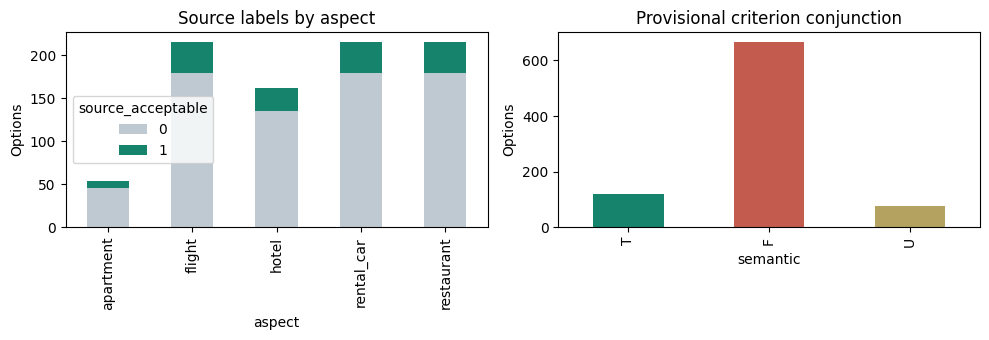

Train template IDs: 241 unique / 384 occurrences
Connected components of train tasks: [96]


In [2]:
display(df.groupby('aspect').agg(options=('option_id','size'),acceptable=('source_acceptable','sum'),best=('source_best','sum')))
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
pd.crosstab(df.aspect,df.source_acceptable).plot.bar(stacked=True,ax=ax[0],color=['#bec9d2','#16846c']);ax[0].set_title('Source labels by aspect');ax[0].set_ylabel('Options')
df.semantic.value_counts().reindex(['T','F','U']).plot.bar(ax=ax[1],color=['#16846c','#c45b4f','#b3a260']);ax[1].set_title('Provisional criterion conjunction');ax[1].set_ylabel('Options')
plt.tight_layout();plt.show()
s=load('results/userbench_train_e025/summary.json')
print('Train template IDs:',s['train_unique_component_ids'],'unique /',s['train_component_id_count'],'occurrences')
print('Connected components of train tasks:',s['train_task_connected_component_sizes'])

Во всех 48 аспектах по 3 source-acceptable варианта из 18 и один source-best. Для бинарного acceptable это 144 положительных и 720 отрицательных строк; для best — 48 и 816. При этом 96 train-задач связаны повторяющимися шаблонами в одну компоненту. Чтобы проверять перенос на новые шаблоны, потребуется другое разбиение или исключение пересекающихся задач. Два примера смены полезного вопроса из E026 имеют общий шаблон перелёта — это не независимая репликация.

## 2. Пропуски и смысл отсутствующих полей

Разные аспекты имеют разные схемы. Например, у ресторанов нет числовой цены — только ценовая категория. Считать её пропуском обычной цены и заполнять средним было бы неверно. В службах явный null означает недоступность услуги по соглашению источника; отсутствующий ключ означает недостаток данных. Нулевой тариф — доступная бесплатная услуга. Эти состояния сохраняем отдельно.

In [3]:
display(df.groupby('aspect')[['base_cost','rating']].agg(lambda x: x.isna().mean()).rename(columns=lambda c:c+'_missing_share'))
miss=[]
for aspect,group in df.groupby('aspect'):
 flat=pd.json_normalize(group.raw.tolist())
 table=pd.DataFrame({'missing_count':flat.isna().sum(),'missing_share':flat.isna().mean()})
 print(aspect, 'within-schema missing-cell fraction:',round(float(flat.isna().to_numpy().mean()),3))
 display(table[table.missing_count>0])
 for parent in ['service','insurance']:
  keys=sorted({k for o in group.raw for k in o.get(parent,{})})
  for key in keys:
   vals=[o.get(parent,{}) for o in group.raw]
   miss.append(dict(aspect=aspect,field=parent+'.'+key,absent=sum(key not in v for v in vals),explicit_null=sum(key in v and v[key] is None for v in vals),numeric_zero=sum(key in v and v[key] is not None and v[key]==0 for v in vals),n=len(vals)))
missing=pd.DataFrame(miss)
for c in ['absent','explicit_null','numeric_zero']:missing[c+'_share']=missing[c]/missing.n
display(missing)

,base_cost_missing_share,rating_missing_share
aspect,,
apartment,0.0,0.0
flight,0.0,1.0
hotel,0.0,0.0
rental_car,0.0,1.0
restaurant,1.0,0.0


apartment within-schema missing-cell fraction: 0.091


,missing_count,missing_share
service.cost_cleaning_total,13,0.240741
service.cost_early_checkin_fee,22,0.407407
service.cost_late_checkout_fee,14,0.259259


flight within-schema missing-cell fraction: 0.123


,missing_count,missing_share
amenities,10,0.046296
company,1,0.004630
service.cost_business_total,21,0.097222
service.cost_check_bag_total,18,0.083333
.company,215,0.995370


hotel within-schema missing-cell fraction: 0.116


... (2 outputs left out)

,missing_count,missing_share
insurance.cost_belonging_waiver,68,0.314815
insurance.cost_damage_waiver,18,0.083333
insurance.cost_liability_waiver,28,0.129630
insurance.cost_personal_accident_waiver,61,0.282407
service.cost_additional_driver_total,42,0.194444
service.cost_child_seat_total,59,0.273148
service.cost_underage_total,86,0.398148


restaurant within-schema missing-cell fraction: 0.018


,missing_count,missing_share
expectation,42,0.194444


,aspect,field,absent,explicit_null,numeric_zero,n,absent_share,explicit_null_share,numeric_zero_share
0,apartment,service.cost_cleaning_total,0,13,1,54,0.0,0.240741,0.018519
1,apartment,service.cost_early_checkin_fee,0,22,1,54,0.0,0.407407,0.018519
2,apartment,service.cost_late_checkout_fee,0,14,1,54,0.0,0.259259,0.018519
3,flight,service.cost_business_total,0,21,8,216,0.0,0.097222,0.037037
4,flight,service.cost_check_bag_total,0,18,8,216,0.0,0.083333,0.037037
5,hotel,service.cost_barrier_free_total,0,71,1,162,0.0,0.438272,0.006173
6,hotel,service.cost_breakfast_total,0,27,2,162,0.0,0.166667,0.012346
7,hotel,service.cost_parking_total,0,71,2,162,0.0,0.438272,0.012346
8,rental_car,service.cost_additional_driver_total,0,42,7,216,0.0,0.194444,0.032407
9,rental_car,service.cost_child_seat_total,0,59,7,216,0.0,0.273148,0.032407


Обработка: исходные данные не исправляем. В производной таблице неприменимые числовые признаки остаются NaN; сравнения выполняем внутри аспекта. Для оценки услуги различаем отсутствующий ключ, null и ноль. Гипотеза о смысле null опирается на инструкции генерации и схему UserBench, а не на статистическую догадку. Подмена неизвестности нулём дала бы ошибочные отрицательные метки.

## 3. Ошибки, выбросы и качество текстов

Проверяем значения рейтинга вне шкалы, отрицательные цены, экстремальные цены и длины текстов. IQR-флаг — повод посмотреть запись, а не автоматически удалить её. В исходных меню специально присутствуют шумовые варианты, включая фантастические предложения. Их нельзя удалять после просмотра ошибок модели: тогда сравнения станут проще задним числом.

Negative numeric prices: 2
Ratings outside 0..10: 14


,aspect,feature,n,iqr_flags,min,max
0,apartment,base_cost,54,6,0.0,5000000.0
1,apartment,rating,54,2,0.0,10.0
2,apartment,text_chars,54,0,225.0,310.0
3,flight,base_cost,216,37,-100.0,10000000.0
4,flight,text_chars,216,12,199.0,382.0
5,hotel,base_cost,162,17,0.0,8888888.0
6,hotel,rating,162,9,-5.0,12.0
7,hotel,text_chars,162,14,240.0,408.0
8,rental_car,base_cost,216,43,-50.0,50000000.0
9,rental_car,text_chars,216,8,333.0,390.0


Repeated IDs inside a menu: 0


status
ambiguous       7
operational    85
unsupported     4
Name: criteria, dtype: int64

Source-correct vs provisional interpretation:


semantic,F,T,U
source_acceptable,,,
0,662,14,44
1,6,105,33


,count,mean,std,min,25%,50%,75%,max
aspect,,,,,,,,
apartment,6.0,139.166667,26.056989,117.0,122.00,131.0,145.25,187.0
flight,24.0,114.291667,24.009924,38.0,100.75,118.0,131.00,149.0
hotel,18.0,114.833333,21.459264,84.0,99.00,110.0,131.50,151.0
rental_car,24.0,127.375000,30.606638,80.0,105.00,125.0,143.00,217.0
restaurant,24.0,130.833333,22.221546,84.0,121.00,128.0,144.00,168.0


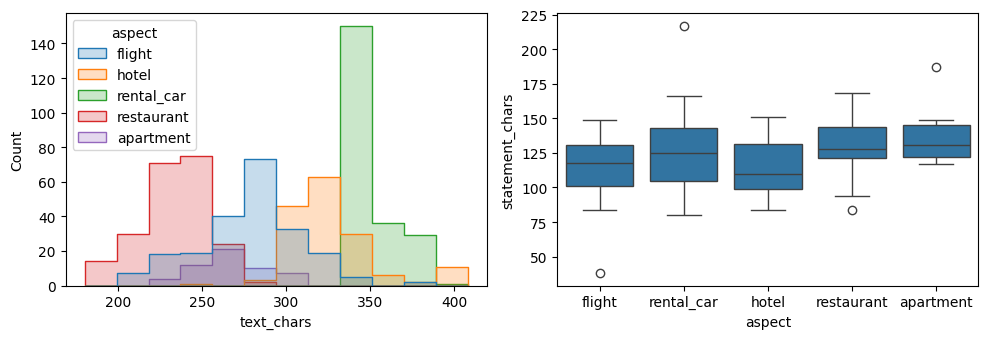

In [4]:
print('Negative numeric prices:',int((df.base_cost.dropna()<0).sum()))
print('Ratings outside 0..10:',int(((df.rating<0)|(df.rating>10)).sum()))
flags=[]
for aspect,g in df.groupby('aspect'):
 for feature in ['base_cost','rating','text_chars']:
  x=g[feature].dropna()
  if len(x):
   q1,q3=x.quantile([.25,.75]);iqr=q3-q1
   flags.append({'aspect':aspect,'feature':feature,'n':len(x),'iqr_flags':int(((x<q1-1.5*iqr)|(x>q3+1.5*iqr)).sum()),'min':x.min(),'max':x.max()})
display(pd.DataFrame(flags))
print('Repeated IDs inside a menu:',int(df.duplicated(['case_id','aspect','option_id']).sum()))
display(pd.DataFrame(criteria).groupby('status').size().rename('criteria'))
print('Source-correct vs provisional interpretation:')
display(pd.crosstab(df.source_acceptable,df.semantic))
pref=pd.DataFrame(criteria)
pref['statement_chars']=pref.implicit_statement.str.len()
display(pref.groupby('aspect').statement_chars.describe())
fig,ax=plt.subplots(1,2,figsize=(10,3.5));sns.histplot(data=df,x='text_chars',hue='aspect',element='step',ax=ax[0]);sns.boxplot(data=pref,x='aspect',y='statement_chars',ax=ax[1]);plt.tight_layout();plt.show()

Найдены 2 отрицательные цены и 14 рейтингов вне диапазона 0–10. Для логарифма цены отрицательные значения заменяем на NaN; для корреляций исключаем рейтинги вне шкалы. Исходные записи сохраняем. IQR-выбросы без дополнительных оснований не удаляем.

Обнаружены содержательные проблемы эталонов: в двух ресторанных задачах текст конкретизирует стейк, а лучший вариант имеет категорию Seafood; в одной задаче с указанным Hong Kong лучший рейс проходит через Los Angeles. У шести ресторанных задач минимум ценовой категории делят несколько вариантов, но source-best один. В all_ids сохранены 192 ссылки на отсутствующие шумовые варианты. Все best/correct ID при этом доступны.

Наш проверяющий код тоже не безошибочен: буквальное Zillow Rental не узнавало Zillow Rentals. Поправка сохранена отдельно, исходный прогон не переписан. После неё 6 из 144 source-acceptable вариантов противоречат хотя бы одному нашему критерию, 33 остаются U. Это согласованность с предварительными правилами, не доказанная частота ошибок всего корпуса. Реальное меню ресторанов, удобство машин и частота уборки этими полями полностью не проверяются.

## 4. Признаки, цель и попарные зависимости

Цена имеет разный смысл у машины, рейса и жилья, поэтому числовые связи считаем отдельно по аспектам. Отсутствие цены у ресторанов не заменяем нулём. Графики ниже описательные: строки зависимы, а сами варианты генерировались под предпочтения, поэтому корреляция не доказывает причинную связь и может отражать способ создания данных.

base_cost  rating  text_chars  attribute_count
aspect     source_acceptable                                                
apartment  0                     2000.0     8.0       262.0              8.0
           1                     1800.0     9.0       295.0              8.0
flight     0                      370.0     NaN       278.0              8.0
           1                      377.5     NaN       294.5              8.0
hotel      0                     1300.0     8.0       318.0              7.0
           1                     1100.0     9.0       363.0              7.0
rental_car 0                      500.0     NaN       348.0              8.0
           1                      610.0     NaN       345.5              8.0
restaurant 0                        NaN     7.0       231.0              7.0
           1                        NaN     8.0       255.5              7.0

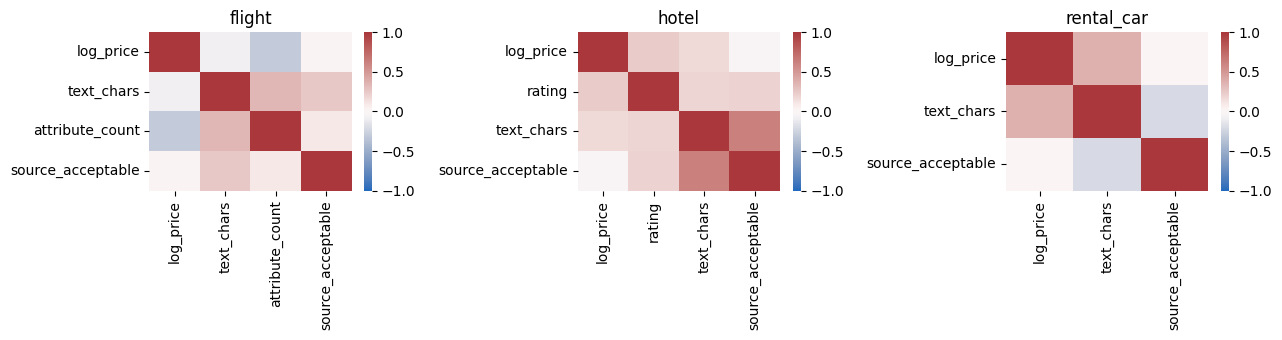

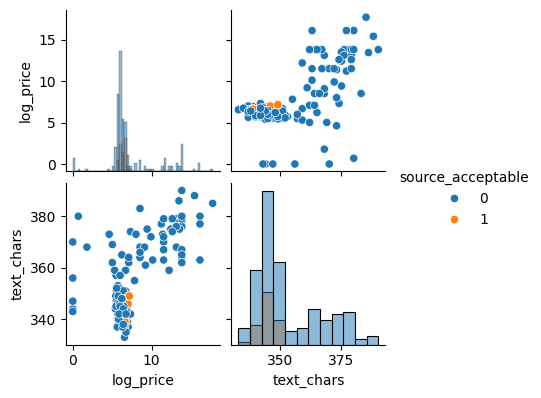

In [5]:
display(df.groupby(['aspect','source_acceptable'])[['base_cost','rating','text_chars','attribute_count']].median())
fig,axs=plt.subplots(1,3,figsize=(13,3.5))
for ax,aspect in zip(axs,['flight','hotel','rental_car']):
 g=df[df.aspect==aspect].copy();g['rating']=g.rating.where(g.rating.between(0,10));g['log_price']=np.log1p(g.base_cost.where(g.base_cost>=0))
 sns.heatmap(g[[c for c in ['log_price','rating','text_chars','attribute_count','source_acceptable'] if g[c].nunique()>1]].corr(method='spearman'),vmin=-1,vmax=1,cmap='vlag',ax=ax);ax.set_title(aspect)
plt.tight_layout();plt.show()
g=df[df.aspect=='rental_car'].copy();g['log_price']=np.log1p(g.base_cost.where(g.base_cost>=0))
sns.pairplot(g[['log_price','text_chars','source_acceptable']],hue='source_acceptable',diag_kind='hist',height=2);plt.show()

Пустые клетки корреляций означают отсутствующий или постоянный признак, а не нулевую связь. В дальнейшем цена и длина текста могут быть признаками, но source-best/source-acceptable, наши критерии и полный скрытый профиль нельзя подавать выбирающему агенту. Для будущей оценки полезности вопроса одного текста и одного профиля недостаточно: потребуется распределение возможных ответов и итогов.

## 5. Простые методы и локальная модель

Сравниваем равномерный выбор, эвристику пересечения слов с предпочтениями (IDF по видимому меню, затем цена) и локальный Qwen3-4B-Instruct-2507 4-bit. Модель не обучалась на этом наборе. Каждый из 192 входов запущен один раз; эталоны в prompt не попадали.

Таблица ниже — диагностика исполнителя: в full ему раскрываются оба предпочтения **для каждого из четырёх аспектов**. Это не результат агента с бюджетом один вопрос. Метрики по источнику и по нашим предварительным критериям показаны отдельно.

In [6]:
summary=load('results/userbench_executor_e027/summary.json')
rows=[]
for policy,modes in summary['all_aspects_same_mask_diagnostic'].items():
 for mode,metrics in modes.items():rows.append({'executor':policy,'mask':mode,**{k:100*float(Fraction(v)) for k,v in metrics.items()}})
display(pd.DataFrame(rows).round(2))
# Independent direct check of model acceptable choices against E025 source labels.
jobs={r['id']:r for r in map(json.loads,(ROOT/'results/userbench_executor_e027/public_inputs.jsonl').read_text().splitlines())}
gens={r['id']:r for r in map(json.loads,(ROOT/'results/userbench_executor_e027/generations.jsonl').read_text().splitlines())}
schedule=load('results/userbench_executor_e027/schedule.json')
hidden={c['case_id']:c for c in gold}; counts={m:0 for m in ['full','no_information','first_only','second_only']}
for e in schedule:
 obj=json.loads(gens[e['id']]['raw_output']);assert set(obj)=={'id'}
 counts[e['mask']]+=obj['id'] in hidden[e['case_id']]['aspects'][e['aspect']]['acceptable_ids']
for mode,n in counts.items():assert Fraction(n,48)==Fraction(summary['all_aspects_same_mask_diagnostic']['qwen3_4b'][mode]['source_acceptable'])
print('Direct source-label recount (48 aspect choices per condition):',counts)
print('Strict semantic reversals for the language executor:',summary['ranking_diagnostics']['qwen3_4b']['robust_semantic_reversals'])

,executor,mask,semantic_lower,semantic_upper,source_acceptable,source_best,valid
0,lexical_price,first_only,39.24,51.74,39.24,18.06,100.0
1,lexical_price,full,43.75,60.42,45.83,23.61,100.0
2,lexical_price,no_information,19.97,30.38,19.44,12.15,100.0
3,lexical_price,second_only,23.44,38.02,26.04,16.67,100.0
4,qwen3_4b,first_only,43.75,56.25,50.00,25.00,100.0
5,qwen3_4b,full,50.00,70.83,64.58,29.17,100.0
6,qwen3_4b,no_information,14.58,20.83,20.83,8.33,100.0
7,qwen3_4b,second_only,33.33,50.00,43.75,22.92,100.0
8,uniform,first_only,13.77,22.69,16.67,5.56,100.0
9,uniform,full,13.77,22.69,16.67,5.56,100.0


Direct source-label recount (48 aspect choices per condition): {'full': 31, 'no_information': 10, 'first_only': 24, 'second_only': 21}
Strict semantic reversals for the language executor: {'first_only': [], 'second_only': []}


По исходной метке acceptable локальная модель получила 10/48 без дополнительных сведений и 31/48 при раскрытии обоих предпочтений по всем аспектам. Простая эвристика — 19,44% и 45,83% соответственно. Эти цифры относятся к знакомым development-задачам и меткам с обнаруженными ограничениями.

При бюджете один вопрос строгая смена единственного лучшего вопроса по семантическим границам у языковой модели не установлена. Поэтому прежний результат символического исполнителя пока нельзя переносить на реального агента. По source-acceptable есть один случай несовпадения полного и частичного ранжирования после контроля ничьих; это диагностическое наблюдение, не подтверждение преимущества обученного выбора вопроса.

## 6. Проверка аугментаций

Проверяем две безопасные для табличного смысла операции: перестановку порядка вариантов и изменение пробелов в текстах. Это тест инвариантности простой эвристики, не языковой модели. Полные/частичные маски также проверены в E026/E027, но они изменяют доступную информацию и не являются безусловно сохраняющей задачу аугментацией. Перефразирование и искусственные опечатки пока не используем для обучения: они могут менять смысл, а независимого контроля нет.

In [7]:
sys.path.insert(0,str(ROOT/'experiments'))
from executors_e027 import lexical_distribution
checks={'option_order':0,'whitespace':0}
for job in jobs.values():
 p=job['payload'];reference=lexical_distribution(p)[0]
 perm=copy.deepcopy(p);perm['options'].reverse();checks['option_order']+=lexical_distribution(perm)[0]==reference
 spaced=copy.deepcopy(p);spaced['trip_request']='  '.join(spaced['trip_request'].split());spaced['additional_statements']=['  '.join(t.split()) for t in spaced['additional_statements']]
 checks['whitespace']+=lexical_distribution(spaced)[0]==reference
assert checks=={'option_order':192,'whitespace':192}
print(checks)

{'option_order': 192, 'whitespace': 192}


## 7. Выводы и дальнейшие действия

1. Задача выбора уточнения сформулирована, но качество конечного решения нельзя свести к совпадению с единственным source-best: часть эталонов неоднозначна или не согласуется с конкретным пожеланием.
2. Пропуски имеют разный смысл. Сохраняем неизвестность, явную недоступность услуги и неприменимость признака раздельно; автоматического заполнения средним нет.
3. Неполные сведения действительно ухудшают работу исполнителя. При этом смена оптимального вопроса, наблюдавшаяся у символического фильтра, не подтвердилась в строгом семантическом критерии у Qwen на этой выборке.
4. Следующий эксперимент должен отделить выбор вопроса от ошибок интерпретации ответа и конечного выбора. Нужны контроль шаблонов, большая выборка, независимая проверка правил и реалистичная модель неполных ответов.
5. Применение — помощники при выборе услуг, товаров и маршрутов: цель уменьшить число бесполезных уточнений и неверных рекомендаций. Практическая оценка требует качества решений при фиксированном числе вопросов, числа вопросов до результата и оценки пользователями; подробности в PDF.

**Ограничения:** 12 уже просмотренных синтетических задач; нет человеческих ответов, независимого теста, доказанной новизны и обученного оценщика полезности вопроса. 864 варианта не являются 864 независимыми задачами. Более ранний анализ синтетического каталога сохранён в outputs/checkpoint2_2026-10-27 и не смешан с этим набором.